# 01 — Inputs: Cardinal → COSMOS2020-like 30-band photometry

This notebook shows how the mock is built and how its photometry compares with the real catalogue.
1. **SEDs**: Cardinal `sedid` → SDSS-VAGC kcorrect `COEFFS` × 5 basis templates. Check: synthetic LSST mags vs the catalogue columns.
2. **Noise**: per band, each simulated galaxy takes the reported error of a random real COSMOS2020 object with the same flux, in the same UltraVISTA ultra-deep/deep region. Extra unreported noise, measured from the real negative-flux tail, is added to the flux realisation; in practice this only affects IRAC.
3. **Photometric sample**: number counts, colour–colour densities and redshift distributions, sim vs data.

Samples: COSMOS2020 CLASSIC clean area (`FLAG_COMBINED==0`). Cardinal: 10.07 deg² patch from triofile 101 (RA 126.7–132.1, Dec 40.5–43.0), including a 2.01 deg² “COSMOS twin” sub-box.

In [1]:
%matplotlib inline
import os, sys
os.environ['PROJ'] = os.path.abspath('..')   # notebooks are executed from notebooks/
sys.path.insert(0, os.environ['PROJ'] + '/scripts')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis_utils import *
plt.rcParams.update({'figure.dpi': 90, 'font.size': 9})
pd.set_option('display.width', 200)

In [2]:
data = pd.read_parquet(f'{PROJ}/data/cosmos2020/cosmos2020_classic_30band.parquet')
data = data[data.FLAG_COMBINED == 0].copy()
sim = pd.read_parquet(f'{PROJ}/work/cardinal/cardinal_patch_cosmos30_obs.parquet')
truth = pd.read_parquet(f'{PROJ}/work/cardinal/cardinal_patch_cosmos30_truemag.parquet')
patch = pd.read_parquet(f'{PROJ}/work/cardinal/cardinal_patch.parquet')
for df in (data, sim):
    add_mags(df); df['i_mag'] = mag(df.f_i)
# areas: sim from the box; data from occupied healpix cells (nside 4096, ~0.74 arcmin^2) of the clean catalogue
import healpy as hp
pix = hp.ang2pix(4096, data.ALPHA_J2000.values, data.DELTA_J2000.values, lonlat=True)
A_pix = len(np.unique(pix)) * hp.nside2pixarea(4096, degrees=True)
A_data = 1.27   # Weaver+22: effective area of FLAG_COMBINED==0 (the occupied-pixel count above over-counts edge pixels)
A_sim = 10.07
print(f'data clean area {A_data} deg2 (occupied-pixel upper bound {A_pix:.2f}), N={len(data)};  sim area {A_sim} deg2, N={len(sim)}')
for c in (24, 25):
    print(f'  i<{c}: data {(data.i_mag < c).sum()/A_data:,.0f} /deg2 (galaxies {((data.i_mag < c) & (data.lp_type == 0)).sum()/A_data:,.0f}),  sim {(sim.i_mag < c).sum()/A_sim:,.0f} /deg2')

data clean area 1.27 deg2 (occupied-pixel upper bound 1.59), N=723897;  sim area 10.07 deg2, N=3025992
  i<24: data 84,647 /deg2 (galaxies 78,601),  sim 70,882 /deg2
  i<25: data 175,317 /deg2 (galaxies 167,201),  sim 140,923 /deg2


## 1. SED reconstruction check
Synthetic LSST magnitudes from the reconstructed SEDs, normalised to the catalogue `mag_i_lsst`, compared with the other catalogue LSST columns. u, g, r and z agree to ≲0.01 mag. y is offset in a redshift-dependent way: Cardinal used a different LSST y curve, and the 4000 Å break crosses the y band at z≈1.5. The COSMOS bands are computed with their own filter curves, so the y offset does not propagate.
At z>1.8 the synthetic u band is fainter than Cardinal's by up to 0.2 mag. Our photometry includes Madau (1995) IGM absorption (the Lyα forest enters u at z≳1.8); the Cardinal catalogue magnitudes evidently do not.

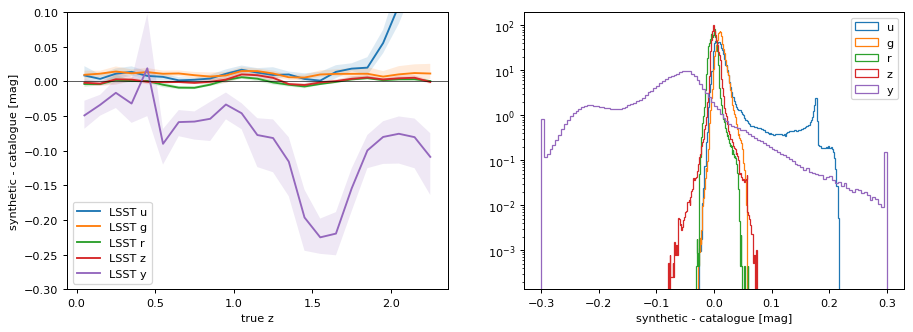

In [3]:
zb = np.arange(0, 2.41, 0.1); zc = 0.5*(zb[1:]+zb[:-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for b in 'ugrzy':
    d = truth[f'mag_lsst_{b}'] - patch[f'mag_{b}_lsst']
    idx = np.digitize(patch.true_redshift, zb) - 1
    q = lambda k, p: np.percentile(d[idx == k], p) if (idx == k).sum() > 10 else np.nan
    med = [q(k, 50) for k in range(len(zc))]; p16 = [q(k, 16) for k in range(len(zc))]; p84 = [q(k, 84) for k in range(len(zc))]
    ax[0].plot(zc, med, label=f'LSST {b}'); ax[0].fill_between(zc, p16, p84, alpha=0.15)
    ax[1].hist(d.clip(-0.3, 0.3), bins=120, histtype='step', label=b, density=True)
ax[0].axhline(0, c='k', lw=0.5); ax[0].set_xlabel('true z'); ax[0].set_ylabel('synthetic - catalogue [mag]'); ax[0].legend(); ax[0].set_ylim(-0.3, 0.1)
ax[1].set_xlabel('synthetic - catalogue [mag]'); ax[1].set_yscale('log'); ax[1].legend()
plt.show()

## 2. Noise model
Left: median reported flux error vs magnitude in each band, for data and sim (UltraVISTA ultra-deep and deep stripes are pooled). Right: the error-calibration test on real data. For objects with negative measured flux, flux/err should be the negative half of a unit Gaussian if the errors are right. IRAC ch1/ch2 fail this badly: deblending/confusion residuals are not in the reported errors. That is why ≈0.1 µJy of extra noise is added to the sim IRAC fluxes.

,sky_err,sig_extra,3sig_reported,3sig_true
u_star,0.0072,0.0053,28.0570,27.8252
u,0.0103,0.0000,27.6785,27.6785
g,0.0052,0.0037,28.4134,28.1898
r,0.0063,0.0000,28.2077,28.2077
i,0.0075,0.0000,28.0154,28.0154
z,0.0125,0.0000,27.4672,27.4672
y,0.0258,0.0000,26.6767,26.6767
Y,0.0472,0.0000,26.0220,26.0220
J,0.0577,0.0000,25.8035,25.8035
H,0.0746,0.0000,25.5255,25.5255


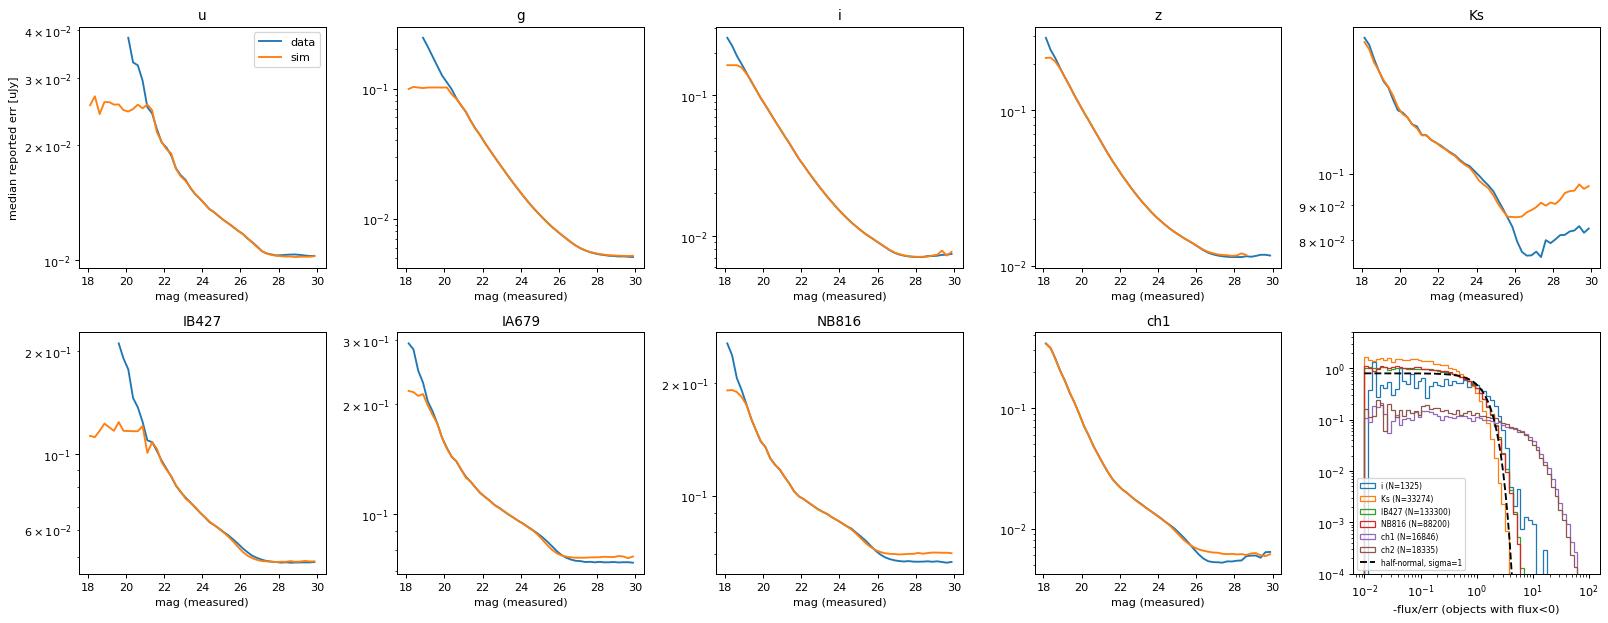

In [4]:
nm = pd.read_csv(f'{PROJ}/work/cardinal/noise_model_summary.csv', index_col=0)
nm['3sig_reported'] = 23.9 - 2.5*np.log10(3*nm.sky_err); nm['3sig_true'] = 23.9 - 2.5*np.log10(3*np.hypot(nm.sky_err, nm.sig_extra))
display(nm.round(4))
show = ['u', 'g', 'i', 'z', 'Ks', 'IB427', 'IA679', 'NB816', 'ch1']
mb = np.arange(18, 30.01, 0.25); mc = 0.5*(mb[1:]+mb[:-1])
fig, axs = plt.subplots(2, len(show)//2+1, figsize=(18, 7)); axs = axs.flat
for k, b in enumerate(show):
    for df, lab in ((data, 'data'), (sim, 'sim')):
        m = mag(df[f'f_{b}']); e = df[f'ferr_{b}']
        idx = np.digitize(m, mb) - 1
        med = [np.nanmedian(e[idx == j]) if (idx == j).sum() > 30 else np.nan for j in range(len(mc))]
        axs[k].plot(mc, med, color=COLORS[lab], label=lab)
    axs[k].set_yscale('log'); axs[k].set_title(b); axs[k].set_xlabel('mag (measured)')
axs[0].set_ylabel('median reported err [uJy]'); axs[0].legend()
ax = axs[len(show)]
for b in ['i', 'Ks', 'IB427', 'NB816', 'ch1', 'ch2']:
    x = (data[f'f_{b}']/data[f'ferr_{b}']).values; x = x[np.isfinite(x) & (x < 0)]
    ax.hist(-x, bins=np.logspace(-2, 2, 60), histtype='step', density=True, label=f'{b} (N={len(x)})')
xx = np.logspace(-2, 2, 200); ax.plot(xx, 2*np.exp(-xx**2/2)/np.sqrt(2*np.pi), 'k--', label='half-normal, sigma=1')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-4, 5); ax.set_xlabel('-flux/err (objects with flux<0)'); ax.legend(fontsize=6)
for a in list(axs)[len(show)+1:]: a.axis('off')
plt.tight_layout(); plt.show()

### Signal-to-noise vs magnitude (measured S/N, i<26)
The sim should follow the data in every band. In the IRAC bands the sim's *reported* S/N matches the data by construction, while its *true* scatter includes the extra noise.

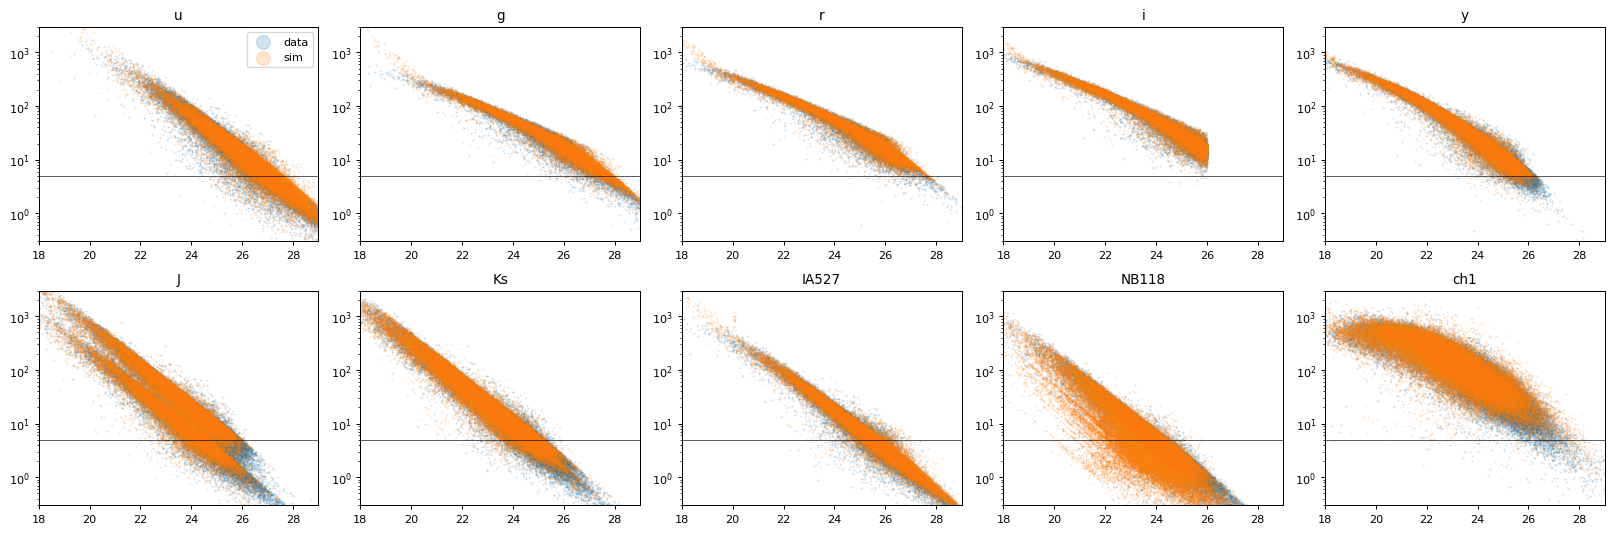

In [5]:
fig, axs = plt.subplots(2, 5, figsize=(18, 6)); axs = axs.flat
for k, b in enumerate(['u', 'g', 'r', 'i', 'y', 'J', 'Ks', 'IA527', 'NB118', 'ch1']):
    for df, lab in ((data, 'data'), (sim, 'sim')):
        s = df[df.i_mag < 26].sample(min(60000, (df.i_mag < 26).sum()), random_state=1)
        axs[k].scatter(mag(s[f'f_{b}']), s[f'f_{b}']/s[f'ferr_{b}'], s=0.3, alpha=0.2, color=COLORS[lab], rasterized=True, label=lab)
    axs[k].set_yscale('log'); axs[k].set_ylim(0.3, 3000); axs[k].set_xlim(18, 29); axs[k].set_title(b); axs[k].axhline(5, c='k', lw=0.5)
axs[0].legend(markerscale=20); plt.tight_layout(); plt.show()

## 3. Number counts
Differential counts per deg² from the measured total magnitudes. The data also contain stars (no stars in the sim), which matter at bright magnitudes. The mock counts turn over at i≈25.5 (Cardinal's galaxy population is incomplete fainter than this), so the photo-z analysis uses i<25. In the NIR/IRAC the mock is brighter at fixed number density, i.e. its galaxies are redder in i−Ks.

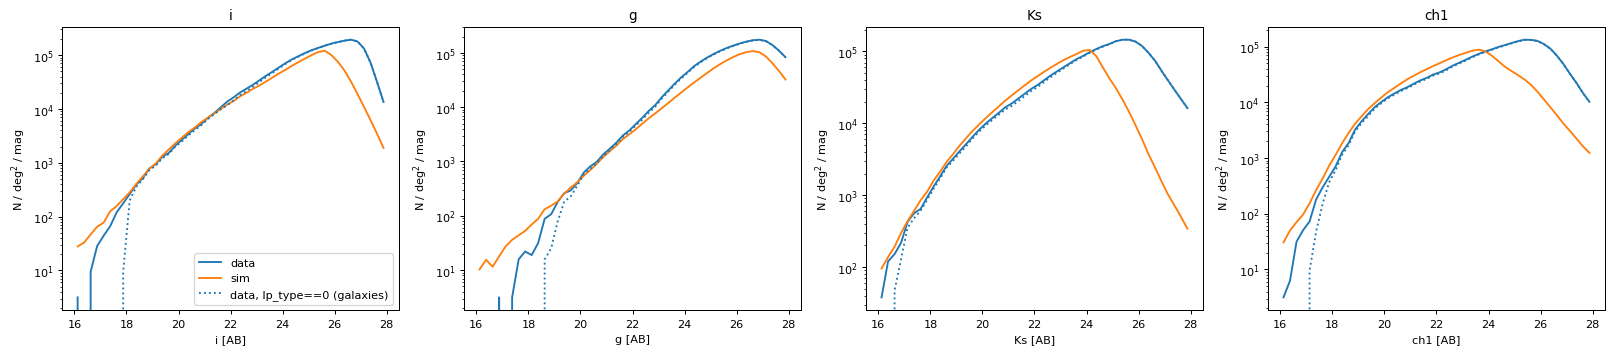

In [6]:
bins = np.arange(16, 28.01, 0.25); bc = 0.5*(bins[1:]+bins[:-1])
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, b in zip(axs, ['i', 'g', 'Ks', 'ch1']):
    for df, A, lab in ((data, A_data, 'data'), (sim, A_sim, 'sim')):
        h = np.histogram(mag(df[f'f_{b}']), bins)[0] / A / 0.25
        ax.plot(bc, h, color=COLORS[lab], label=lab)
    ds = data[data.lp_type == 0]
    ax.plot(bc, np.histogram(mag(ds[f'f_{b}']), bins)[0]/A_data/0.25, color=COLORS['data'], ls=':', label='data, lp_type==0 (galaxies)')
    ax.set_yscale('log'); ax.set_xlabel(f'{b} [AB]'); ax.set_ylabel('N / deg$^2$ / mag'); ax.set_title(b)
axs[0].legend(); plt.tight_layout(); plt.show()

## 4. Colour distributions (i < 25)
Contours enclose 50/80/95% of the density. Galaxy colours in the mock come from a library of low-z SDSS galaxies placed on a light cone, so differences here are the main limitation of the mock.

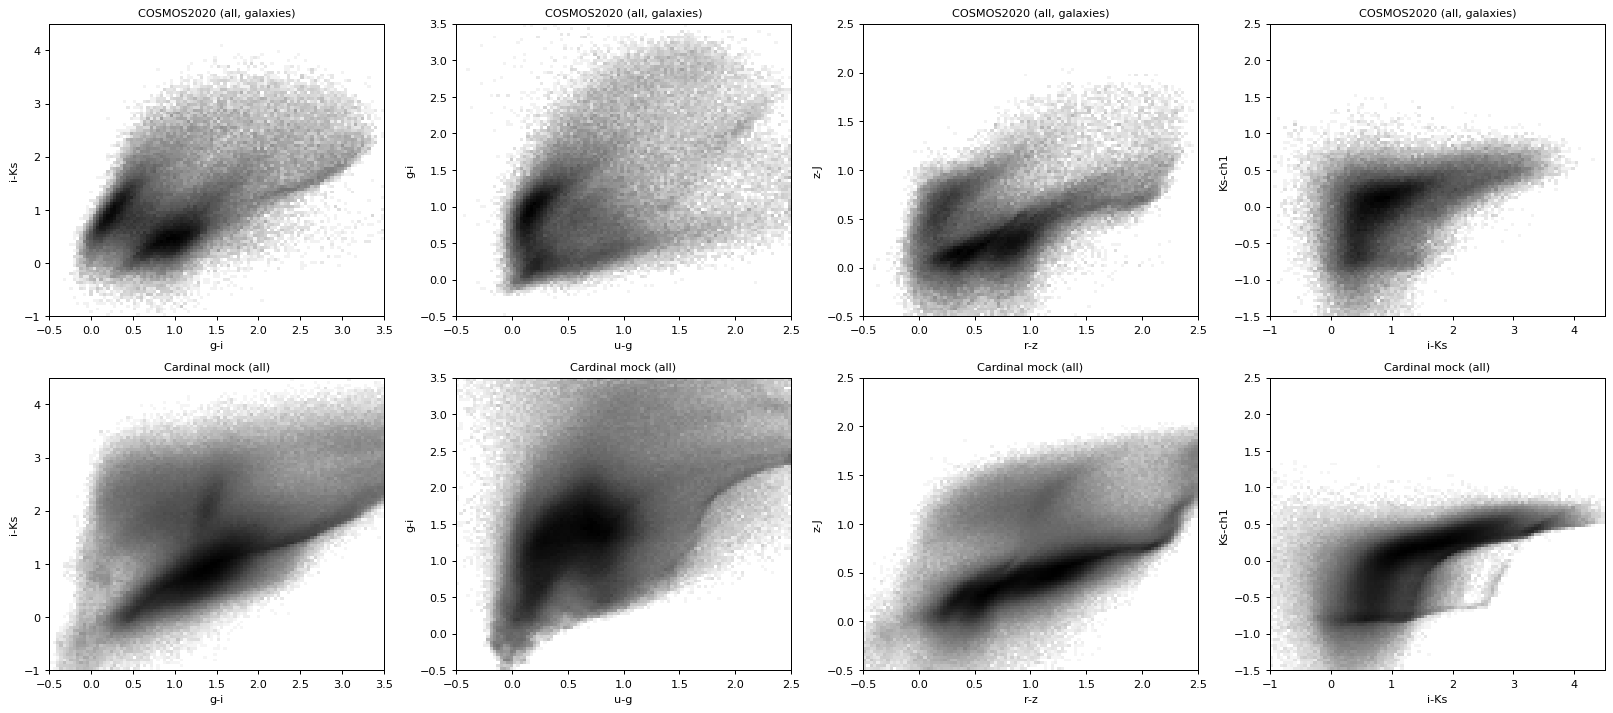

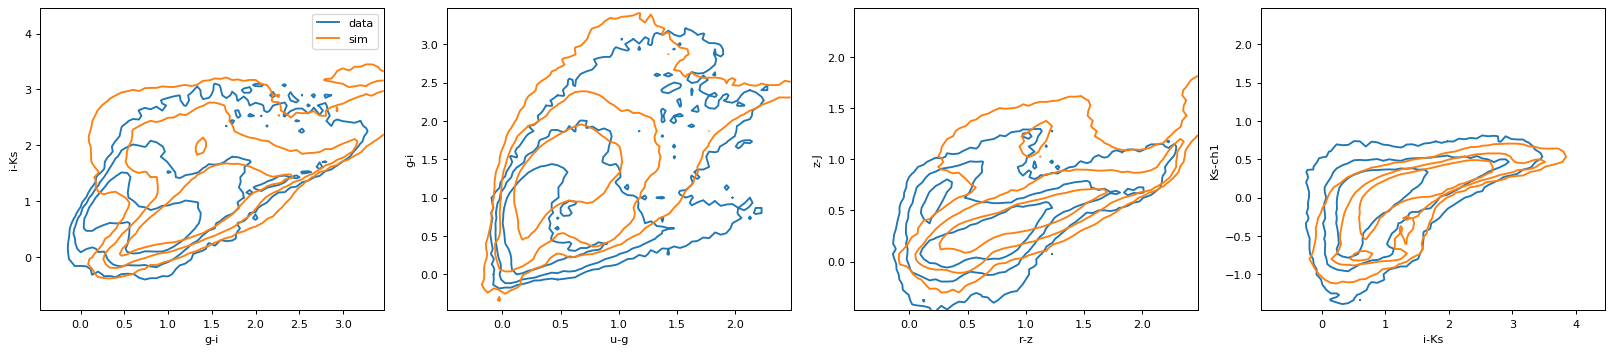

In [7]:
pairs = [('g_i', 'i_Ks', 'g-i', 'i-Ks', (-0.5, 3.5), (-1, 4.5)), ('u_g', 'g_i', 'u-g', 'g-i', (-0.5, 2.5), (-0.5, 3.5)),
         ('r_z', 'z_J', 'r-z', 'z-J', (-0.5, 2.5), (-0.5, 2.5)), ('i_Ks', 'Ks_ch1', 'i-Ks', 'Ks-ch1', (-1, 4.5), (-1.5, 2.5))]
dsel, ssel = data[(data.i_mag < 25) & (data.lp_type == 0)], sim[sim.i_mag < 25]
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for k, (x, y, xl, yl, xr, yr) in enumerate(pairs):
    for r, (df, lab) in enumerate(((dsel, 'data'), (ssel, 'sim'))):
        axs[r, k].hist2d(df[x], df[y], bins=100, range=[xr, yr], cmap='Greys', norm=LogNorm(), rasterized=True)
        axs[r, k].set_title(f'{LABELS[lab] if lab=="sim" else "COSMOS2020 (all, galaxies)"}', fontsize=9)
        axs[r, k].set_xlabel(xl); axs[r, k].set_ylabel(yl)
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for k, (x, y, xl, yl, xr, yr) in enumerate(pairs):
    for df, lab in ((dsel, 'data'), (ssel, 'sim')):
        H, xe, ye = np.histogram2d(df[x], df[y], bins=60, range=[xr, yr], density=True)
        Hs = np.sort(H.ravel())[::-1]; c = np.cumsum(Hs)/Hs.sum()
        lev = sorted(Hs[np.searchsorted(c, q)] for q in (0.95, 0.8, 0.5))
        axs[k].contour(0.5*(xe[1:]+xe[:-1]), 0.5*(ye[1:]+ye[:-1]), H.T, levels=lev, colors=COLORS[lab])
        axs[k].plot([], [], color=COLORS[lab], label=lab)
    axs[k].set_xlabel(xl); axs[k].set_ylabel(yl)
axs[0].legend(); plt.tight_layout(); plt.show()

### 1-D colour distributions in i-magnitude brackets

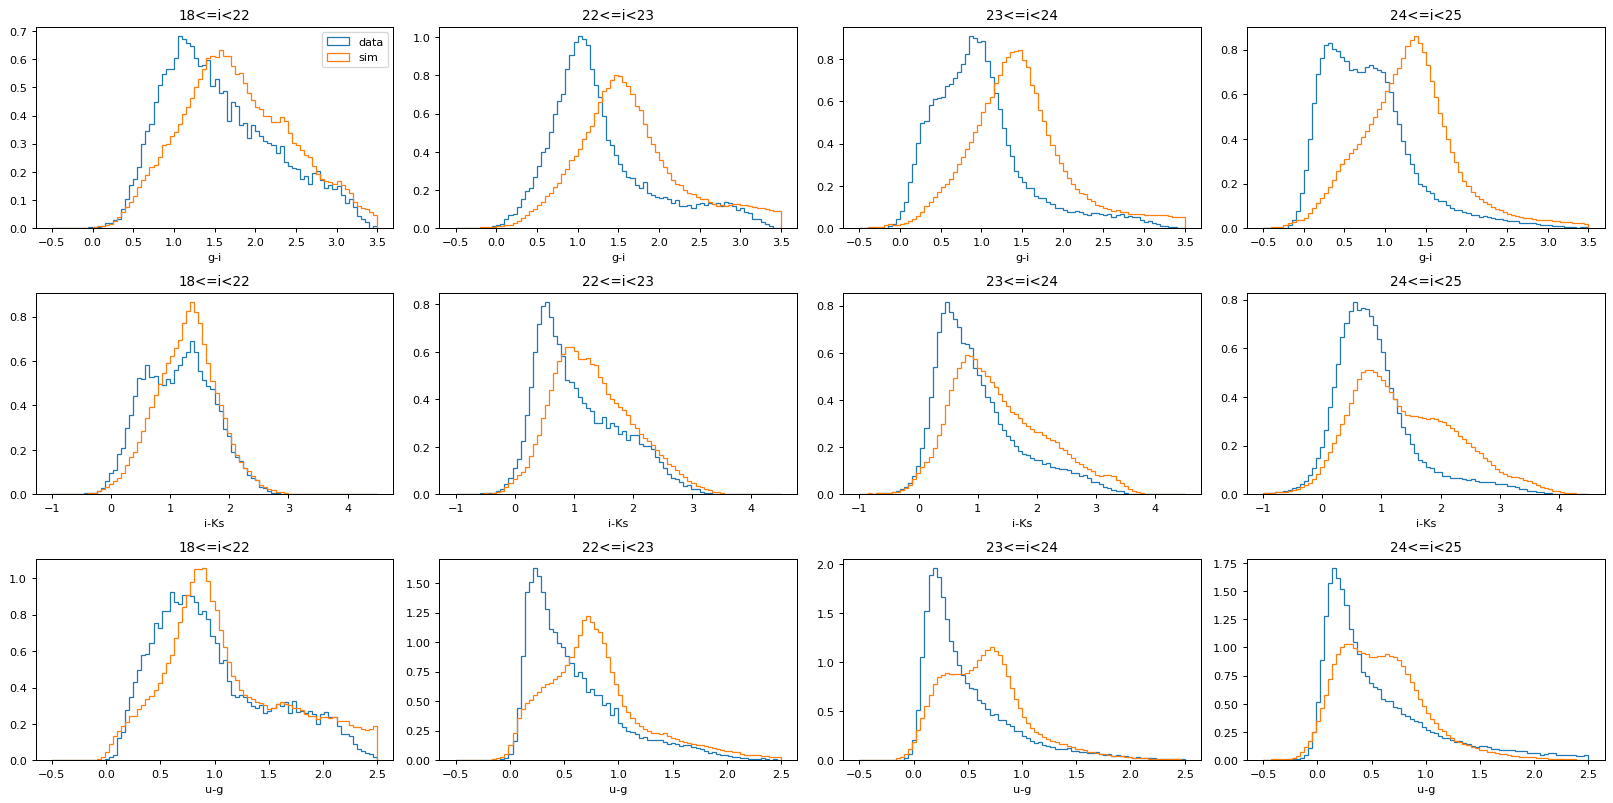

In [8]:
brk = [(18, 22), (22, 23), (23, 24), (24, 25)]
fig, axs = plt.subplots(3, 4, figsize=(18, 9))
for r, (c, rng_) in enumerate([('g_i', (-0.5, 3.5)), ('i_Ks', (-1, 4.5)), ('u_g', (-0.5, 2.5))]):
    for k, (lo, hi) in enumerate(brk):
        for df, lab in ((data[data.lp_type == 0], 'data'), (sim, 'sim')):
            v = df[(df.i_mag >= lo) & (df.i_mag < hi)][c]
            axs[r, k].hist(v, bins=80, range=rng_, histtype='step', density=True, color=COLORS[lab], label=lab)
        axs[r, k].set_title(f'{lo}<=i<{hi}'); axs[r, k].set_xlabel(c.replace('_', '-'))
axs[0, 0].legend(); plt.tight_layout(); plt.show()

## 5. Redshift distributions
Sim: true z. Data: official COSMOS2020 `lp_zBEST` for the photometric sample, and the spec-z sample (which is biased to bright galaxies and particular populations).

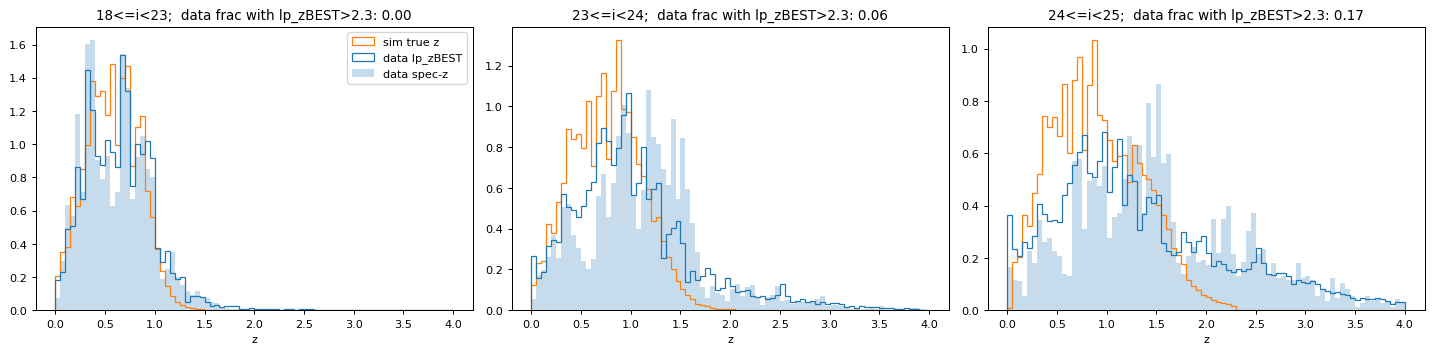

In [9]:
brk = [(18, 23), (23, 24), (24, 25)]
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, (lo, hi) in zip(axs, brk):
    d = data[(data.i_mag >= lo) & (data.i_mag < hi) & (data.lp_type == 0)]
    s = sim[(sim.i_mag >= lo) & (sim.i_mag < hi)]
    ax.hist(s.true_redshift, bins=80, range=(0, 4), histtype='step', density=True, color=COLORS['sim'], label='sim true z')
    ax.hist(d.lp_zBEST, bins=80, range=(0, 4), histtype='step', density=True, color=COLORS['data'], label='data lp_zBEST')
    ax.hist(d.z_spec.dropna(), bins=80, range=(0, 4), histtype='stepfilled', alpha=0.25, density=True, color='C0', label='data spec-z')
    ax.set_title(f'{lo}<=i<{hi};  data frac with lp_zBEST>2.3: {(d.lp_zBEST > 2.3).mean():.2f}'); ax.set_xlabel('z')
axs[0].legend(); plt.tight_layout(); plt.show()

## Key findings
1. **SEDs.** Cardinal's `sedid` → VAGC kcorrect `COEFFS` reproduces the catalogue LSST colours to ≲0.01 mag (u, g, r, z). The y band offset comes from a different y curve, and the z>1.8 u offset from our IGM treatment.
2. **Noise.** The empirical error model reproduces the reported COSMOS2020 errors in every band. The real IRAC (CLASSIC) errors are ~8× too small for faint sources (negative-flux test), so the mock IRAC fluxes carry an extra ≈0.10 µJy of noise (true 3σ ≈25.2). One known imperfection: in sparsely populated *bright* bins (e.g. u<21) the mock takes sky-limited errors. This is irrelevant for photo-z because LePhare's ERR_SCALE floor (0.02–0.05 mag) dominates there.
3. **Counts.** At i<25 the mock has 141k gal/deg² vs 167k for COSMOS2020 galaxies (−16%). The mock is incomplete beyond i≈25.5.
4. **Colours.** The mock covers the main COSMOS colour loci but with different weights: more red g−i at faint magnitudes, a redder i−Ks, a narrower blue cloud, and sharp, template-like features in Ks−ch1. The mock also has no galaxies above z≈2.3, whereas 17% of COSMOS2020 galaxies at 24<i<25 are at z>2.3.